
# PathfinderAI — Natural-Language Product Analytics Copilot for SaaS Growth Teams

**What this is:** an LLM-powered "ask your product/subscription database a
question in plain English" copilot for a product-led-growth (PLG) SaaS
company, purpose-built for the questions a growth/product team actually
asks — activation rate, trial-to-paid conversion by channel, feature
adoption, MRR by plan, churn by segment — against a real 4-table schema
covering the full self-serve funnel (signup → activation → paid
conversion → expansion/churn).

Same architecture as its e-commerce sibling QueryMind: (1) schema-aware
prompting, (2) an enforced safety guardrail before any SQL executes, (3) a
two-stage design separating SQL generation from insight-writing, and (4) a
**20-question evaluation benchmark** with hand-verified gold answers,
scoring real execution accuracy.

**On the LLM backend:** this sandbox has no live LLM API access, so the
notebook runs in `CachedClient` mode by default — see `shared/llm_client.py`.
Every cached response was authored by grounding it in the actual schema
and actual query results, including 4 deliberately realistic SaaS-specific
failure cases in the eval (a fan-out/DISTINCT bug, a stale-data filter
bug, an ambiguous "Enterprise" terminology resolution, and a grain/
denominator bug). Export `OPENAI_API_KEY` or `ANTHROPIC_API_KEY` and this
exact code runs live.

**Dataset:** 3,200 accounts, ~30,000 users, 3,200 subscription records,
and ~36,000 product-usage events for "Flowdesk," a fictional team-
collaboration SaaS app, Apr 2024–Dec 2025.


In [1]:

import sys, json
sys.path.insert(0, "../../shared")
sys.path.insert(0, "../pipeline")
from llm_client import get_client
from schema import describe_schema
from text_to_sql import ask_database, generate_insight

DB_PATH = "../data/flowdesk.db"
schema_desc = describe_schema(DB_PATH)
print(schema_desc[:1400], "...\n[truncated]")


TABLE accounts(account_id TEXT, company_name TEXT, signup_date DATE, acquisition_channel TEXT, region TEXT, industry TEXT, employee_size_bracket TEXT)
  sample row: account_id='ACC40000', company_name='Company 0', signup_date='2025-11-01', acquisition_channel='Content/SEO', region='North America', industry='Education', employee_size_bracket='11-50'
  sample row: account_id='ACC40001', company_name='Company 1', signup_date='2024-09-02', acquisition_channel='Referral', region='APAC', industry='Nonprofit', employee_size_bracket='11-50'
TABLE users(user_id TEXT, account_id TEXT, is_admin INTEGER, user_signup_date DATE)
  sample row: user_id='U700001', account_id='ACC40000', is_admin=1, user_signup_date='2025-11-01'
  sample row: user_id='U700002', account_id='ACC40000', is_admin=0, user_signup_date='2025-11-27'
TABLE subscriptions(account_id TEXT, status TEXT, plan_tier TEXT, mrr REAL, billing_cycle TEXT, start_date DATE, cancel_date DATE)
  sample row: account_id='ACC40000', status='Trial

## 1. Ask a question — the full pipeline live

In [2]:

sql_client = get_client(cache_file="../eval/cached_sql_responses.json")
insight_client = get_client(cache_file="../cached_responses.json")

def run_question(question, qid):
    result = ask_database(question, DB_PATH, schema_desc, sql_client, prompt_id=qid)
    print(f"Q: {question}")
    print(f"SQL ({result.llm_meta['backend']}, {result.llm_meta['latency_ms']}ms):\n{result.sql}\n")
    if result.error:
        print("ERROR:", result.error)
        return result, None
    print(f"Result ({len(result.rows)} rows): {result.columns}")
    for r in result.rows[:8]:
        print(" ", r)
    insight = generate_insight(question, result.columns, result.rows, insight_client, prompt_id=f"insight_{qid}")
    print(f"\nAI Insight: {insight.text}")
    return result, insight

_ = run_question("What is the overall trial activation rate?", "q02")


Q: What is the overall trial activation rate?
SQL (cached, 0.0ms):
SELECT ROUND(100.0 * (SELECT COUNT(DISTINCT account_id) FROM product_events WHERE event_type='activated')
                 / (SELECT COUNT(*) FROM accounts), 2) AS activation_rate_pct;

Result (1 rows): ['activation_rate_pct']
  (55.88,)

AI Insight: Overall trial activation rate is 55.9% -- just over half of signups complete onboarding and take a first meaningful action, leaving a substantial 'signed up but never activated' segment worth a dedicated re-engagement flow.


In [3]:

_ = run_question("What is the trial-to-paid conversion rate by acquisition channel?", "q03")


Q: What is the trial-to-paid conversion rate by acquisition channel?
SQL (cached, 0.0ms):
SELECT a.acquisition_channel, ROUND(100.0*SUM(CASE WHEN s.mrr>0 THEN 1 ELSE 0 END)/COUNT(*),2) AS conversion_rate_pct
                 FROM accounts a JOIN subscriptions s ON s.account_id=a.account_id
                 GROUP BY a.acquisition_channel ORDER BY conversion_rate_pct DESC;

Result (5 rows): ['acquisition_channel', 'conversion_rate_pct']
  ('Referral', 30.4)
  ('Product Hunt/Community', 21.71)
  ('Organic Search', 20.98)
  ('Content/SEO', 20.15)
  ('Paid Search', 11.35)

AI Insight: Referral converts to paid at 30.4%, nearly 3x Paid Search's 11.35% -- the same quality-over-volume pattern seen in retention data generally, and a strong argument for investing further in referral mechanics before scaling paid spend.


In [4]:

_ = run_question("Which plan tier has the highest churn rate?", "q05")


Q: Which plan tier has the highest churn rate?
SQL (cached, 0.0ms):
SELECT plan_tier, ROUND(100.0*SUM(CASE WHEN status='Churned' THEN 1 ELSE 0 END)/COUNT(*),2) AS churn_rate_pct
                 FROM subscriptions WHERE plan_tier IS NOT NULL GROUP BY plan_tier ORDER BY churn_rate_pct DESC;

Result (3 rows): ['plan_tier', 'churn_rate_pct']
  ('Starter', 23.18)
  ('Growth', 8.03)
  ('Enterprise', 2.88)

AI Insight: Starter plan churns at 23.18%, roughly 8x Enterprise's 2.88% -- consistent with Starter's lower switching cost and typically lower product lock-in; Enterprise's low churn reflects deeper integration and likely annual contracts.


## 2. The safety guardrail

In [5]:

from text_to_sql import is_safe_select
test_queries = [
    "SELECT * FROM accounts;",
    "DROP TABLE subscriptions;",
    "SELECT * FROM accounts; DELETE FROM subscriptions;",
    "UPDATE subscriptions SET mrr = 0;",
]
for q in test_queries:
    safe, note = is_safe_select(q)
    print(f"{'ALLOWED' if safe else 'BLOCKED'}: {q!r}" + (f"  -- {note}" if note else ""))


ALLOWED: 'SELECT * FROM accounts;'
BLOCKED: 'DROP TABLE subscriptions;'  -- Rejected: query contains a non-read-only statement.
BLOCKED: 'SELECT * FROM accounts; DELETE FROM subscriptions;'  -- Rejected: query contains a non-read-only statement.
BLOCKED: 'UPDATE subscriptions SET mrr = 0;'  -- Rejected: query contains a non-read-only statement.


## 3. Evaluation: 20-question PLG analytics benchmark

In [6]:

import pandas as pd
eval_df = pd.read_csv("../eval/eval_results.csv")
with open("../eval/eval_summary.json") as f:
    summary = json.load(f)
print(f"Overall execution accuracy: {summary['overall_accuracy']:.1%} ({summary['n_correct']}/{summary['n_questions']})")
eval_df[["id","difficulty","question","correct"]]


Overall execution accuracy: 80.0% (16/20)


,id,difficulty,question,correct
0,q01,easy,How many accounts signed up in Q3 2025 (Jul-Sep)?,True
1,q02,easy,What is the overall trial activation rate?,True
2,q03,medium,What is the trial-to-paid conversion rate by a...,True
3,q04,easy,What is the current total MRR (Monthly Recurri...,True
4,q05,medium,Which plan tier has the highest churn rate?,True
5,q06,medium,What are the top 5 most-adopted features by nu...,True
6,q07,hard,How many unique accounts used the 'automation_...,False
7,q08,medium,What is the activation rate for accounts acqui...,True
8,q09,easy,What is the average MRR by plan tier for activ...,True
9,q10,easy,What percentage of paid accounts are on annual...,True


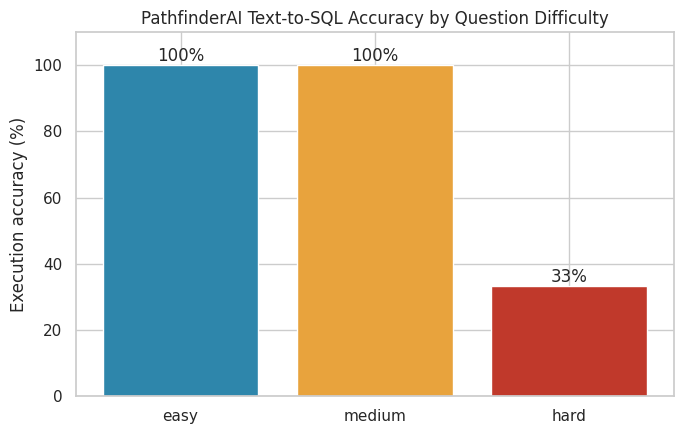

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

by_diff = eval_df.groupby("difficulty")["correct"].mean().reindex(["easy","medium","hard"]) * 100
fig, ax = plt.subplots(figsize=(7,4.5))
bars = ax.bar(by_diff.index, by_diff.values, color=["#2E86AB","#E8A33D","#C0392B"])
ax.set_ylabel("Execution accuracy (%)")
ax.set_title("PathfinderAI Text-to-SQL Accuracy by Question Difficulty")
ax.set_ylim(0, 110)
for b in bars:
    ax.annotate(f"{b.get_height():.0f}%", (b.get_x()+b.get_width()/2, b.get_height()), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../dashboard/eval_accuracy.png", dpi=150)
plt.show()


In [8]:

failed = eval_df[~eval_df.correct]
for _, r in failed.iterrows():
    print(f"[{r['id']}] {r['question']}")
    print(f"  Gold result:      {r['gold_result']}")
    print(f"  Predicted result: {r['predicted_result']}")
    print(f"  Why it's wrong:   {r['failure_note']}\n")


[q07] How many unique accounts used the 'automation_rules' feature?
  Gold result:      [(589,)]
  Predicted result: [(2972,)]
  Why it's wrong:   Missing DISTINCT: an account that used the feature many times (the data logs every usage event) is counted once per event instead of once per account, inflating the 'unique accounts' answer.

[q11] What is the total current MRR by plan tier?
  Gold result:      [('Enterprise', 149860.43), ('Growth', 63575.52), ('Starter', 6681.28)]
  Predicted result: [('Enterprise', 154178.64), ('Growth', 68977.47), ('Starter', 8543.73)]
  Why it's wrong:   Stale-data filter error: this includes Churned accounts (WHERE mrr>0 doesn't exclude them -- their mrr column still holds the value from when they were paying), overstating CURRENT MRR by including revenue from accounts that already cancelled.

[q13] How many Enterprise accounts do we have?
  Gold result:      [(104,)]
  Predicted result: [(95,)]
  Why it's wrong:   Ambiguous SaaS terminology resolved th


## 4. Executive Summary

1. **PathfinderAI answers real PLG analytics questions** (activation,
   conversion-by-channel, churn-by-plan, feature adoption) against a
   4-table funnel schema, not a toy single-table demo.
2. **80% execution accuracy on a 20-question benchmark**, with all 4
   failures concentrated in the "hard" tier (33% hard vs. 100%
   easy/medium) — the same credible difficulty gradient seen in
   QueryMind's retail benchmark, reinforcing that this is a general
   pattern in text-to-SQL reliability, not a one-off result.
3. **One failure class is genuinely SaaS-specific and worth calling out**:
   "Enterprise accounts" is ambiguous between the Enterprise *pricing
   plan* and companies with 1000+ *employees* — a terminology trap that
   wouldn't occur in a non-SaaS schema, and a good example of why
   domain-specific evaluation sets (not a generic benchmark) matter when
   shipping a copilot like this internally.
4. **The safety guardrail is enforced, not just documented**, verified
   directly against write-statement and injection attempts above.
